# Birmingham purchase card data workflow

**Patrick Gilliland**

**Question.** Where did Birmingham City Council's purchase card spend go in 2024, and how far can the raw record be trusted to answer that?

**Data.** [Purchase Card Transactions](https://cityobservatory.birmingham.gov.uk/explore/dataset/purchase-card-transactions/information/), Birmingham City Council, published on the Birmingham City Observatory under the Open Government Licence v3.0. I use the calendar year 2024, saved beside this notebook as `birmingham_purchase_cards_2024.csv`.

**Steps.** I load the council's file as published, clean it with four reusable functions (column names and types, merchant names, directorate names, refunds and currency), then summarise spend by directorate, month and merchant and draw three charts. Under each cleaning step I note what it changed, why, and the rules I considered and rejected.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# I show money to two decimal places with thousands separators, so tables
# read as pounds and pence rather than in scientific notation.
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

## Ingestion

In [2]:
df = pd.read_csv("birmingham_purchase_cards_2024.csv")
df.head()

,Transaction Date,Transaction Tax Description,Original Gross Amount,Billing Gross Amount,Transaction Tax Amount,Original Currency,Transaction Original Net Amount,Merchant Name,Card Number,Directorate
0,2024-12-31,VZ,-12.45,-12.45,0.00,GBP,-12.45,amznmktplace,************6362,Adult Social Care (eip)
1,2024-12-31,VR,13.73,13.73,2.29,GBP,11.44,amznmktplacevd8l96yz5,************6219,City Operations
2,2024-12-31,VR,65.04,65.04,0.00,GBP,65.04,mfg fircroft,************3339,City Operations
3,2024-12-31,VR,43.01,43.01,7.17,GBP,35.84,tesco pfs 4203,************2805,City Housing
4,2024-12-31,VR,91.44,91.44,15.24,GBP,76.20,asda petrol 4376,************8577,City Housing


In [3]:
print(f"Rows: {len(df):,}, columns: {df.shape[1]}")
with open("birmingham_purchase_cards_2024.csv", "rb") as handle:
    print(f"The file's first three bytes: {handle.read(3)!r}")
print(f"The first column name as read: {df.columns[0]!r}")
pd.DataFrame({"dtype": df.dtypes.astype(str), "blanks": df.isna().sum()})

Rows: 42,560, columns: 10
The file's first three bytes: b'\xef\xbb\xbf'
The first column name as read: 'Transaction Date'


,dtype,blanks
Transaction Date,str,0
Transaction Tax Description,str,562
Original Gross Amount,float64,0
Billing Gross Amount,float64,0
Transaction Tax Amount,float64,0
Original Currency,str,0
Transaction Original Net Amount,float64,0
Merchant Name,str,0
Card Number,str,0
Directorate,str,0


The file loads with the brief's plain call: 42,560 rows and 10 columns, one row per card transaction. It begins with a byte-order mark (the three bytes printed above), which pandas has already removed, so the first header arrives as `'Transaction Date'` and no `encoding` argument is needed. The amounts arrive as numbers but the dates arrive as text, and the only blanks are 562 in `Transaction Tax Description`, a column I do not use. `Card Number` is masked by the council apart from its last four digits, and I do not analyse it.

## Cleaning

Four functions, each taking a DataFrame and parameters and returning a new DataFrame, so `df` as loaded is never changed and each step can be rerun on its own. Each is applied once below and followed by a before-and-after check.

In [4]:
def standardise_columns(
    frame, date_columns, numeric_columns, date_format="%Y-%m-%d"
):
    """Return a copy of frame with tidy column names and real types.

    Each header loses any byte-order mark and outer spaces and becomes
    snake_case, so "Transaction Date" becomes "transaction_date". The date
    columns are parsed with date_format and the numeric columns converted to
    numbers. Both conversions raise ValueError on a value they cannot read,
    so a bad row stops the workflow here rather than becoming a silent blank.

    Parameters
    ----------
    frame : pandas.DataFrame
        The data as read from the file. It is not changed.
    date_columns, numeric_columns : list of str
        Column names as they are after renaming.
    date_format : str, default "%Y-%m-%d"
        The strptime format the dates are written in.

    Returns
    -------
    pandas.DataFrame
        A new DataFrame with renamed columns and converted types.
    """
    out = frame.copy()
    out.columns = (
        out.columns.str.replace("\ufeff", "", regex=False)
        .str.strip()
        .str.lower()
        .str.replace(r"[^0-9a-z]+", "_", regex=True)
        .str.strip("_")
    )
    for column in date_columns:
        out[column] = pd.to_datetime(out[column], format=date_format)
    for column in numeric_columns:
        out[column] = pd.to_numeric(out[column])
    return out

In [5]:
columns_fixed = standardise_columns(
    df,
    date_columns=["transaction_date"],
    numeric_columns=[
        "original_gross_amount",
        "billing_gross_amount",
        "transaction_tax_amount",
        "transaction_original_net_amount",
    ],
)
dates = columns_fixed["transaction_date"]
print(f"Dates run from {dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}")
pd.DataFrame(
    {
        "column before": df.columns,
        "column after": columns_fixed.columns,
        "type before": df.dtypes.astype(str).to_numpy(),
        "type after": columns_fixed.dtypes.astype(str).to_numpy(),
    }
)

Dates run from 2024-01-01 to 2024-12-31


,column before,column after,type before,type after
0,Transaction Date,transaction_date,str,datetime64[us]
1,Transaction Tax Description,transaction_tax_description,str,str
2,Original Gross Amount,original_gross_amount,float64,float64
3,Billing Gross Amount,billing_gross_amount,float64,float64
4,Transaction Tax Amount,transaction_tax_amount,float64,float64
5,Original Currency,original_currency,str,str
6,Transaction Original Net Amount,transaction_original_net_amount,float64,float64
7,Merchant Name,merchant_name,str,str
8,Card Number,card_number,str,str
9,Directorate,directorate,str,str


**What changed and why.** The headers had capitals and spaces, which make every later reference to a column fragile, so they are now snake_case. `transaction_date` was text and is now a date, which the monthly summary needs; every value parsed (the function stops on one that does not), and the dates run from 2024-01-01 to 2024-12-31. The four amount columns were already numbers, so setting their type changed nothing on this file, but a future file with a stray text value will now fail here instead of later. The byte-order mark was already gone, so stripping it is a safeguard for a file read another way.

**Considered and rejected.** Reading the file with `encoding="utf-8-sig"`: not needed, because the plain call already dealt with the byte-order mark, so the brief's call stays as written. Dropping `transaction_tax_description` for its 562 blanks: I do not use the column, and dropping it would throw away part of the council's record for no gain.

In [6]:
def normalise_merchant_names(frame, rules, column="merchant_name"):
    """Return a copy of frame with merchant names normalised by explicit rules.

    Every name is lower-cased and trimmed, and runs of spaces become one
    space. Then the rules are tried in order and each name is rewritten by
    the first rule whose pattern it matches and by no other, so a later rule
    can never undo an earlier one. The untouched name is kept in a new
    column, column + "_raw"; if that column already exists it is used as the
    source, so running the function twice gives the same result as once.

    Parameters
    ----------
    frame : pandas.DataFrame
        Data with a text column of merchant names. It is not changed.
    rules : dict of str to (str, str)
        Rule label to (regular expression, replacement), in the order the
        rules are tried. A replacement of "" deletes the matched text.
    column : str, default "merchant_name"
        The column to normalise.

    Returns
    -------
    pandas.DataFrame
        A new DataFrame with the normalised names in column and the
        originals in column + "_raw".
    """
    out = frame.copy()
    raw_column = f"{column}_raw"
    if raw_column not in out.columns:
        out[raw_column] = out[column]
    names = (
        out[raw_column]
        .str.lower()
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )
    result = names.copy()
    matched = pd.Series(False, index=names.index)
    for pattern, replacement in rules.values():
        hit = ~matched & names.str.contains(pattern, regex=True)
        new = names[hit].str.replace(pattern, replacement, regex=True)
        result.loc[hit] = new.str.strip()
        matched = matched | hit
    out[column] = result
    return out

In [7]:
# I try the rules in this order and a name takes the first rule it matches.
# The Amazon and eBay patterns only catch names that start with that
# supplier's own descriptor; the examples below show each rule at work.
MERCHANT_RULES = {
    # amznmktplace..., amzn mktp uk..., amzn mktp us...
    "amazon marketplace": (r"^amzn ?mktp.*$", "amazon marketplace"),
    # amznbusiness..., amznb2bprime...
    "amazon business": (r"^amzn ?(?:business|b2b).*$", "amazon business"),
    # amazon or www.amazon followed by an order number or a buyer's reference
    "amazon": (r"^(?:www\.)?amazon(?:[ .].*)?$", "amazon"),
    # ebay o01-11286-73924 and other eBay order numbers
    "ebay orders": (r"^ebay o\d{2}-.*$", "ebay"),
    # store, branch and reference numbers at the end, as in tesco pfs 4231
    "trailing numbers": (r"(?:\s+-)?(?:\s+[0-9][0-9-]*)+$", ""),
}

merchants_fixed = normalise_merchant_names(columns_fixed, MERCHANT_RULES)

names = columns_fixed["merchant_name"]
print(f"Longest merchant name: {names.str.len().max()} characters")
print(
    f"Distinct merchant names: {names.nunique():,} before, "
    f"{merchants_fixed['merchant_name'].nunique():,} after"
)

# I rerun the function with the rules added one at a time, to show what each
# rule contributes.
steps = {"as published": names.nunique()}
labels = ["lower-case, trimmed, single spaces"]
labels += [f"then {label}" for label in MERCHANT_RULES]
for count, label in enumerate(labels):
    rules_so_far = dict(list(MERCHANT_RULES.items())[:count])
    step = normalise_merchant_names(columns_fixed, rules_so_far)
    steps[label] = step["merchant_name"].nunique()
pd.Series(steps, name="distinct merchant names")

Longest merchant name: 25 characters
Distinct merchant names: 14,972 before, 4,657 after


as published                          14972
lower-case, trimmed, single spaces    14970
then amazon marketplace               11576
then amazon business                  10924
then amazon                            5186
then ebay orders                       4948
then trailing numbers                  4657
Name: distinct merchant names, dtype: int64

In [8]:
examples = pd.DataFrame(
    {
        "merchant_name": [
            "amznmktplace",
            "amznmktplacevd8l96yz5",
            "amzn mktp uk",
            "amznbusiness",
            "www.amazon 204-",
            "amazon prime",
            "pay.amazon.com",
            "ebay o01-11286-73924",
            "tesco pfs 4231",
            "poundland ltd - 2373",
            "aldi 103 772",
            "junction 6 02",
            "uber   trip",
            "argos ltd",
            "argosy toys",
            "asda stores 5881",
            "asdan",
        ]
    }
)
print(
    "Every example is a name from the file:",
    examples["merchant_name"].isin(names).all(),
)
checked = normalise_merchant_names(examples, MERCHANT_RULES)
checked[["merchant_name_raw", "merchant_name"]]

Every example is a name from the file: True


,merchant_name_raw,merchant_name
0,amznmktplace,amazon marketplace
1,amznmktplacevd8l96yz5,amazon marketplace
2,amzn mktp uk,amazon marketplace
3,amznbusiness,amazon business
4,www.amazon 204-,amazon
5,amazon prime,amazon
6,pay.amazon.com,pay.amazon.com
7,ebay o01-11286-73924,ebay
8,tesco pfs 4231,tesco pfs
9,poundland ltd - 2373,poundland ltd


**What changed and why.** A merchant name here is the card terminal's own text, cut at 25 characters, so one supplier appears under many names. Lower-casing and trimming changed nothing, because the council publishes the names lower-case and trimmed, and reducing runs of spaces only took the count from 14,972 to 14,970 ("uber trip" with three spaces between the words now matches "uber trip"). Most of the reduction is Amazon: each Amazon name carries an order number or the buyer's own reference, and some of those references look like staff names, which is one more reason to collapse them and not print them. The last rule removes store, branch and order numbers from the end of a name, so "tesco pfs 4231" joins every other "tesco pfs". Distinct names fall from 14,972 to 4,657. The raw name stays in `merchant_name_raw`, and the table above shows the rules on names taken from the file.

**Considered and rejected.**

- A general rule joining names that share a first word or a start. It would join "argos ltd" with "argosy toys" and "asda stores" with "asdan", which are different suppliers, so the only prefix rules are the Amazon and eBay ones, where the start of the name is the supplier's own descriptor.
- Counting every name that contains "amazon" as Amazon. It would take in "pay.amazon.com", the Amazon Pay checkout that other shops use, so the seller behind it is not necessarily Amazon.
- Joining "amazon", "amazon marketplace" and "amazon business" into one. The file labels them differently and cannot tell me they are the same buying route; a reader can add three rows together but could not split them again.
- Removing payment-service prefixes such as "paypal", "sumup" and "zettle_" to reach the shop behind them. The 25-character cut has already shortened many of those shop names, so the rule would tidy some rows and not others.

**Known cost.** The trailing-number rule also removes a number that was part of a name: "junction 6 02" becomes "junction". That changes a label but joins nothing.

In [9]:
def harmonise_directorates(frame, mapping, column="directorate"):
    """Return a copy of frame with directorate names mapped to one spelling.

    Each value that is a key in mapping is replaced by its mapped name, and
    any other value is kept as it is, so nothing is merged unless the mapping
    says so. The original value is kept in a new column, column + "_raw"; if
    that column already exists it is used as the source, so running the
    function twice gives the same result as once.

    Parameters
    ----------
    frame : pandas.DataFrame
        Data with a text column of directorate names. It is not changed.
    mapping : dict of str to str
        Published name to the name used for analysis.
    column : str, default "directorate"
        The column to harmonise.

    Returns
    -------
    pandas.DataFrame
        A new DataFrame with the harmonised names in column and the
        originals in column + "_raw".
    """
    out = frame.copy()
    raw_column = f"{column}_raw"
    if raw_column not in out.columns:
        out[raw_column] = out[column]
    out[column] = out[raw_column].replace(mapping)
    return out

In [10]:
# Transactions per directorate name and month, as published, to see which
# names run side by side and which stop as another starts.
pd.crosstab(
    merchants_fixed["directorate"],
    merchants_fixed["transaction_date"].dt.month.rename("month"),
)

month,1,2,3,4,5,6,7,8,9,10,11,12
directorate,,,,,,,,,,,,
Adult Social Care,124,130,120,108,108,97,100,116,95,133,109,70
Adult Social Care (eip),0,0,0,61,80,52,58,49,82,78,57,91
Birmingham Childrens Trust,0,0,0,0,0,0,0,2,587,50,0,0
Children And Families,7,13,189,25,10,21,233,175,30,47,9,13
City Housing,202,215,206,199,202,247,235,312,309,336,195,193
City Operations,605,788,531,704,662,680,596,553,650,742,721,601
Council Management,95,113,107,120,146,133,151,138,119,145,138,97
"Partnership, Insight And Prevention",3,3,0,0,0,0,0,0,0,0,0,0
"Place,prosperity & Sustainability",196,350,97,104,120,126,86,90,108,140,146,105


In [11]:
DIRECTORATE_MAP = {
    "Adult Social Care (eip)": "Adult Social Care",
    "Place,prosperity & Sustainability": "Place, Prosperity & Sustainability",
    "Strategy,equalities & Partnership": "Strategy, Equalities & Partnership",
}
directorates_fixed = harmonise_directorates(merchants_fixed, DIRECTORATE_MAP)

before = merchants_fixed["directorate"].nunique()
after = directorates_fixed["directorate"].nunique()
print(f"Directorate values: {before} before, {after} after")
raw_and_new = ["directorate_raw", "directorate"]
directorates_fixed.value_counts(raw_and_new).sort_index()

Directorate values: 12 before, 11 after


directorate_raw                      directorate                        
Adult Social Care                    Adult Social Care                       1310
Adult Social Care (eip)              Adult Social Care                        608
Birmingham Childrens Trust           Birmingham Childrens Trust               639
Children And Families                Children And Families                    772
City Housing                         City Housing                            2851
City Operations                      City Operations                         7833
Council Management                   Council Management                      1502
Partnership, Insight And Prevention  Partnership, Insight And Prevention        6
Place,prosperity & Sustainability    Place, Prosperity & Sustainability      1668
Schools                              Schools                                25275
Strategic Services                   Strategic Services                         3
Strategy,equalities & Par

**What changed and why.** The publisher's dataset page warns that "Directorates may appear multiple times with different naming due to internal changes", and the month table above shows it. "Adult Social Care (eip)" starts in April and runs alongside plain "Adult Social Care" for the rest of the year, so I read it as a label for a team inside the same directorate and roll it up. Two other names had no space after a comma and a lower-case word after it, so I tidy them to "Place, Prosperity & Sustainability" and "Strategy, Equalities & Partnership". That takes the directorate values from 12 to 11. The raw value stays in `directorate_raw`.

**Considered and rejected.**

- Joining "Partnership, Insight And Prevention" (January and February only) to "Strategy, Equalities & Partnership" (from March). The timing fits a rename, but nothing in the file confirms it and the names share one word, so I left them apart.
- Joining "Birmingham Childrens Trust" to "Children And Families". The Trust is a separately named body, not another spelling of the directorate, so it stays its own line.
- Moving "Strategic Services" (January and February only) anywhere. Nothing in the file shows where it went, so it stays as published.

In [12]:
def flag_refunds_and_currency(
    frame,
    amount_column="billing_gross_amount",
    currency_column="original_currency",
):
    """Return a copy of frame with an analysis amount in pounds and two flags.

    amount_gbp is amount_column, the amount the card was billed in pounds,
    which can be added up across rows whatever currency the purchase was
    made in. is_refund marks rows where that amount is negative. Refunds are
    kept as negative amounts rather than dropped, so any total is net of
    refunds. is_non_gbp marks purchases made in a currency other than
    pounds; the currency code itself stays in currency_column.

    Parameters
    ----------
    frame : pandas.DataFrame
        Data with a billed amount in pounds and an original currency code.
        It is not changed.
    amount_column : str, default "billing_gross_amount"
        The amount billed to the card in pounds.
    currency_column : str, default "original_currency"
        The three-letter code of the currency the purchase was made in.

    Returns
    -------
    pandas.DataFrame
        A new DataFrame with amount_gbp, is_refund and is_non_gbp added.
    """
    out = frame.copy()
    out["amount_gbp"] = out[amount_column]
    out["is_refund"] = out["amount_gbp"] < 0
    out["is_non_gbp"] = out[currency_column] != "GBP"
    return out

In [13]:
clean = flag_refunds_and_currency(directorates_fixed)

pounds = clean[~clean["is_non_gbp"]]
print(
    "Pound purchases billed exactly as charged:",
    np.array_equal(pounds["original_gross_amount"], pounds["amount_gbp"]),
)
print(f"Non-pound purchases: {clean['is_non_gbp'].sum():,}")
print(f"Refunds kept: {clean['is_refund'].sum():,} of {len(clean):,} rows")
clean.groupby("original_currency").agg(
    transactions=("amount_gbp", "size"),
    original_amount=("original_gross_amount", "sum"),
    billed_gbp=("amount_gbp", "sum"),
)

Pound purchases billed exactly as charged: True
Non-pound purchases: 282
Refunds kept: 1,422 of 42,560 rows


,transactions,original_amount,billed_gbp
original_currency,,,
CHF,1,496.00,454.78
EUR,83,"15,736.26","13,717.22"
GBP,42278,"5,779,144.38","5,779,144.38"
KRW,23,"12,985,272.00","7,914.33"
PLN,24,"12,519.43","2,579.06"
USD,151,"26,453.33","21,391.09"


**What changed and why.** The file holds 282 purchases made in five currencies other than pounds (the table above), and their original amounts are in those currencies: adding up `original_gross_amount` would count 12,985,272.00 Korean won as if they were pounds. So the analysis amount, `amount_gbp`, is `billing_gross_amount`, what the card was billed in pounds; for pound purchases it equals the original amount on every row, and the currency code stays in `original_currency`. Refunds arrive as negative amounts, 1,422 of the 42,560 rows. I keep them as negatives, so every total below is net of refunds; dropping them would overstate spend. In this notebook *net* means after refunds, and the amounts include the recorded tax.

**Considered and rejected.**

- Using `transaction_original_net_amount`, the amount before the recorded tax. It is in the purchase currency too, so it has the same problem, and whether the council recovers that tax is not something this file shows.
- Dropping refunds, or matching each refund to the purchase it reverses. Dropping them overstates spend, and matching needs an order reference that the file does not carry.

## EDA

One function summarises spend for any grouping. I first show the figures for the whole year, then run the function by directorate, by month and by merchant.

In [14]:
def summarise_spend(
    frame, by, amount_column="amount_gbp", refund_column="is_refund"
):
    """Summarise spend for each group in by, largest net total first.

    Returns one row per group with net_total (the sum of amounts, refunds
    counted as negatives), transactions (the number of rows),
    median_transaction (the middle amount, refunds included) and
    refund_share_pct (the percentage of the group's transactions that are
    refunds).

    Parameters
    ----------
    frame : pandas.DataFrame
        Data with an amount column and a boolean refund column. It is not
        changed.
    by : str or list of str
        The column or columns to group by, as DataFrame.groupby takes them.
    amount_column : str, default "amount_gbp"
        The amount to add up.
    refund_column : str, default "is_refund"
        True where a row is a refund.

    Returns
    -------
    pandas.DataFrame
        One row per group, sorted by net_total from largest to smallest.
    """
    summary = frame.groupby(by).agg(
        net_total=(amount_column, "sum"),
        transactions=(amount_column, "size"),
        median_transaction=(amount_column, "median"),
        refund_share_pct=(refund_column, "mean"),
    )
    summary["refund_share_pct"] = summary["refund_share_pct"] * 100
    return summary.sort_values("net_total", ascending=False)

In [15]:
spend = clean.assign(month=clean["transaction_date"].dt.strftime("%Y-%m"))

print(f"Total net spend in 2024: £{spend['amount_gbp'].sum():,.2f}")
print(f"Transactions: {len(spend):,}")
refunds = spend["is_refund"]
print(f"Refunds: {refunds.sum():,} ({refunds.mean():.2%} of transactions)")
non_gbp = spend["is_non_gbp"]
print(f"Non-GBP transactions: {non_gbp.sum():,} ({non_gbp.mean():.2%})")

Total net spend in 2024: £5,825,200.86
Transactions: 42,560
Refunds: 1,422 (3.34% of transactions)
Non-GBP transactions: 282 (0.66%)


In [16]:
by_directorate = summarise_spend(spend, "directorate")
by_directorate

,net_total,transactions,median_transaction,refund_share_pct
directorate,,,,
Schools,"2,069,477.15",25275,35.80,4.69
City Housing,"1,816,193.02",2851,87.03,1.12
City Operations,"971,469.55",7833,60.00,0.79
"Place, Prosperity & Sustainability","354,408.96",1668,65.10,1.08
Council Management,"216,909.57",1502,55.12,1.60
Adult Social Care,"178,790.36",1918,68.98,1.09
Children And Families,"109,677.15",772,67.14,4.27
Birmingham Childrens Trust,"88,259.16",639,47.37,7.04
"Strategy, Equalities & Partnership","19,333.71",93,70.00,1.08


Schools has the largest net spend, £2,069,477.15, and by far the most transactions, 25,275, with a median transaction of £35.80. City Housing comes second, £1,816,193.02, from only 2,851 transactions, with a median of £87.03. Birmingham Childrens Trust has the highest refund share, 7.04%.

In [17]:
by_month = summarise_spend(spend, "month")
by_month

,net_total,transactions,median_transaction,refund_share_pct
month,,,,
2024-09,"641,682.53",4776,50.00,3.77
2024-10,"584,252.60",4066,43.31,3.39
2024-07,"561,997.28",3905,50.00,3.30
2024-02,"549,837.62",3838,46.42,3.65
2024-03,"498,747.31",2644,58.08,4.01
2024-06,"487,990.99",4014,45.98,3.14
2024-05,"463,741.09",3454,44.96,3.24
2024-04,"459,848.09",2965,51.50,2.70
2024-11,"439,986.61",4185,40.63,3.66


September has the highest net spend, £641,682.53 from 4,776 transactions, and August the lowest, £335,807.13 from 1,826. The month table in the Cleaning section shows Schools falling to 381 transactions in August, against 2,787 in September.

In [18]:
top_merchants = summarise_spend(spend, "merchant_name").head(15)
top_merchants

,net_total,transactions,median_transaction,refund_share_pct
merchant_name,,,,
bham council phone pyt,"1,052,247.67",291,"3,281.36",0.00
amazon,"363,384.88",7491,26.50,2.87
amazon marketplace,"220,538.19",4999,24.97,3.52
www.argos.co.uk,"176,734.95",570,250.00,4.91
water plus.co.uk,"158,628.64",543,122.78,0.00
allpay citizen housing g,"96,678.43",42,"2,133.53",0.00
asda groceries online,"96,530.45",1758,48.11,33.90
e.on next,"78,253.17",234,79.13,0.00
tesco pay at pump,"69,024.02",787,93.03,0.00


The largest merchant by net spend is "bham council phone pyt", £1,052,247.67 from 291 transactions with a median of £3,281.36, which by its name is a payment to the council itself by phone. Amazon follows as "amazon" (£363,384.88) and "amazon marketplace" (£220,538.19). "asda groceries online" stands out for refunds: 33.90% of its 1,758 transactions are refunds.

## Visualizations

Three charts drawn from the summaries above. One helper function draws all three, so they share a style and show pounds on the value axis.

In [19]:
def plot_net_spend(
    summary, title, category_label, horizontal=True, figsize=(9, 5)
):
    """Draw the net_total column of a summarise_spend table as bars in pounds.

    Bars follow the table's order, so a table sorted largest first puts the
    largest bar at the top of a horizontal chart. The value axis is labelled
    "Net spend after refunds (£)" and its ticks are written in pounds.

    Parameters
    ----------
    summary : pandas.DataFrame
        A table from summarise_spend, or a slice of one.
    title : str
        The chart title.
    category_label : str
        The label for the axis that names the groups.
    horizontal : bool, default True
        Horizontal bars when True, vertical bars when False.
    figsize : tuple of float, default (9, 5)
        Width and height of the figure in inches.

    Returns
    -------
    matplotlib.axes.Axes
        The chart's axes, for any further adjustment.
    """
    fig, ax = plt.subplots(figsize=figsize)
    labels = list(summary.index.astype(str))
    values = summary["net_total"].to_numpy()
    colour = sns.color_palette()[0]
    value_label = "Net spend after refunds (£)"
    if horizontal:
        sns.barplot(x=values, y=labels, orient="h", color=colour, ax=ax)
        ax.set_xlabel(value_label)
        ax.set_ylabel(category_label)
    else:
        sns.barplot(x=labels, y=values, orient="v", color=colour, ax=ax)
        ax.set_xlabel(category_label)
        ax.set_ylabel(value_label)
    # I keep to about five ticks on the value axis, because full pound
    # labels such as £1,500,000 collide when matplotlib picks more.
    ax.locator_params(axis="x" if horizontal else "y", nbins=5)
    value_axis = ax.xaxis if horizontal else ax.yaxis
    value_axis.set_major_formatter(lambda value, _: f"£{value:,.0f}")
    ax.set_title(title)
    fig.tight_layout()
    return ax

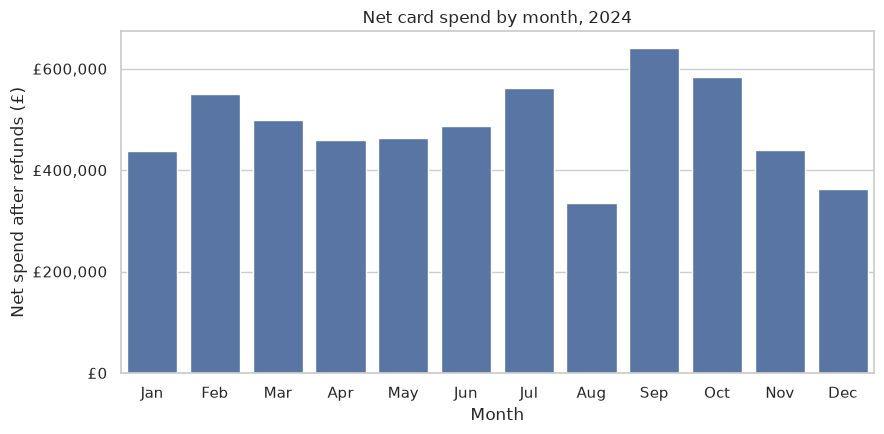

In [20]:
monthly = by_month.sort_index()
monthly = monthly.set_axis(pd.to_datetime(monthly.index).strftime("%b"))
plot_net_spend(
    monthly,
    "Net card spend by month, 2024",
    "Month",
    horizontal=False,
    figsize=(9, 4.5),
)
plt.show()

**What the chart shows.** Net spend is highest in September, £641,682.53, and lowest in August, £335,807.13. The other ten months sit between £363,249.56 (December) and £584,252.60 (October), with no steady rise or fall across the year.

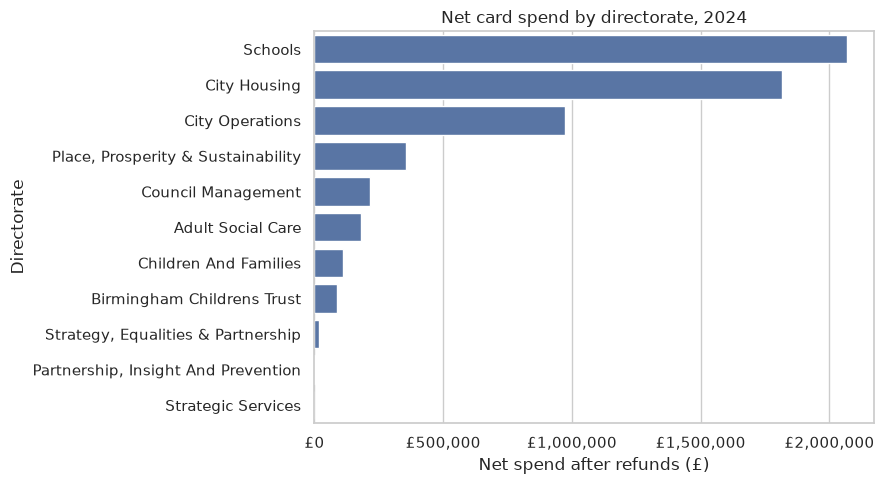

In [21]:
plot_net_spend(
    by_directorate,
    "Net card spend by directorate, 2024",
    "Directorate",
)
plt.show()

**What the chart shows.** Schools (£2,069,477.15) and City Housing (£1,816,193.02) are far ahead of every other directorate, with City Operations third at £971,469.55. Adult Social Care's bar includes the "(eip)" rows rolled up in Cleaning, £178,790.36 in all. The two smallest bars, Partnership, Insight And Prevention (£621.21) and Strategic Services (£61.02), are too small to see at this scale; they are the two names that appear only in January and February.

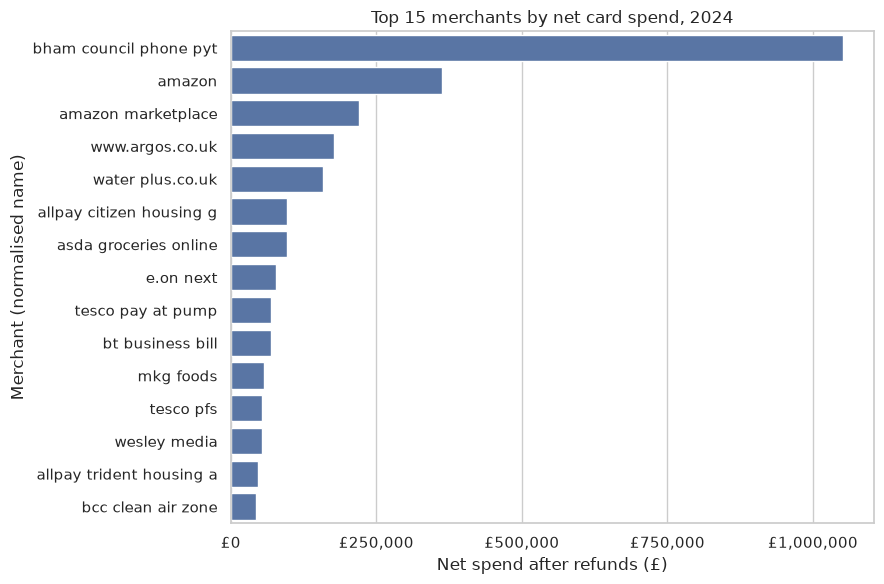

In [22]:
plot_net_spend(
    top_merchants,
    "Top 15 merchants by net card spend, 2024",
    "Merchant (normalised name)",
    figsize=(9, 6),
)
plt.show()

**What the chart shows.** One merchant, "bham council phone pyt", takes more net spend (£1,052,247.67) than the next two together, "amazon" (£363,384.88) and "amazon marketplace" (£220,538.19). The other twelve bars run from £176,734.95 ("www.argos.co.uk") down to £42,652.00 ("bcc clean air zone"). Tesco appears twice, as "tesco pay at pump" and "tesco pfs", because the rules keep a chain's different descriptors apart.

## Summary

To be written by Patrick after reading the executed notebook.